# Asteroid pairs: two orbits, one body, a few centuries ago

**The question.** Some asteroids come in pairs: two bodies on orbits so alike that they must have
been one object that split, usually by spinning itself apart. The age of a pair is read from the
orbits: integrate both backwards and find the moment they coincided. The youngest known pairs are
astonishingly young, centuries rather than millions of years. Can PyRoOrb's fits, propagated
backwards as clouds of covariance clones, reproduce the published ages, and what decides whether
such a test works at all?

Two pairs with very different stories:

* **(458271) 2010 UM26 and 2010 RN221**, a main-belt pair that Vokrouhlický et al. (2022, A&A
  664, L17) date to about **March 2003**: the clones meet within a few hundred km at a few cm/s,
  with no planetary encounter in the way. Jewitt et al. (2023, AJ 166, 191) measured the bodies.
* **2019 PR2 and 2019 QR6**, the "youngest pair" of the press releases (Fatka et al. 2022, MNRAS
  510, 6033), with an age of about **300 years**. Both bodies passed Jupiter some 406 years ago, and
  gravity alone never brings them closer than tens of thousands of km: the published age needs
  comet-like outgassing forces on the pair.

The convergence test is the standard one (Pravec et al. 2010, Nature 466, 1085): clone pairs must
come within a few Hill radii of the primary at a relative speed of a few times its escape speed.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyroorb

pyroorb.load_settings()       # the .env settings file (data folders), before the first fit
pyroorb.asteroid_perturbers() # the 16 most massive asteroids perturb every fit (notebook 02)

# Future UTC dates make astropy warn that leap seconds are not yet known; harmless here.
warnings.filterwarnings("ignore", message=".*dubious year.*")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3})
print("PyRoOrb", pyroorb.__version__)

PyRoOrb 0.9.0


## 1. Four fits, two pairs

The elements say "pair" at a glance: within each pair *a*, *e*, *i* and the orientation angles agree
to a few parts in a thousand. (They are osculating elements at each fit's own epoch, so the last
digits differ for two reasons: the epochs are not the same, and the orbits really have drifted apart
since the split. The backward integration is what turns that small difference into an age.)

In [2]:
from astropy.time import Time

PAIRS = {"UM26 / RN221": ("458271", "2010 RN221"), "PR2 / QR6": ("2019 PR2", "2019 QR6")}
fits = {}
for pair, members in PAIRS.items():
    for d in members:
        obs = pyroorb.fetch_observations(d)
        fits[d] = pyroorb.fit_orbit(obs, designation=d)
        f = fits[d]
        print(f"{d:12s} {f.n_observations():4d} obs, arc {f.arc_length_days() / 365.25:4.1f} yr, "
              f"rms {f.rms_residual():.2f}\", H {f.absolute_magnitude()[0]:.1f}, {f.force_model}")

rows = []
for d, f in fits.items():
    el, sg = f.elements(), f.element_sigmas()
    rows.append({"object": d, **{k: f"{el[k]:.6f} ± {sg[k]:.0e}" for k in ("a", "e", "i", "asc_node", "arg_per")}})
pd.DataFrame(rows).set_index("object")

458271        231 obs, arc 19.9 yr, rms 0.39", H 17.8, ASSIST(DE440+GR+16ast)


2010 RN221     47 obs, arc 19.9 yr, rms 0.24", H 19.2, ASSIST(DE440+GR+16ast)


2019 PR2      389 obs, arc 14.4 yr, rms 1.38", H 18.8, ASSIST(DE440+GR+16ast)


2019 QR6      145 obs, arc 14.4 yr, rms 0.23", H 20.1, ASSIST(DE440+GR+16ast)


,a,e,i,asc_node,arg_per
object,,,,,
458271,2.575984 ± 2e-08,0.327470 ± 6e-08,3.860093 ± 6e-06,235.408944 ± 9e-05,119.139108 ± 9e-05
2010 RN221,2.578002 ± 4e-08,0.324423 ± 1e-07,3.880000 ± 8e-06,234.917398 ± 1e-04,120.262527 ± 1e-04
2019 PR2,5.772109 ± 7e-08,0.797688 ± 2e-08,10.990064 ± 4e-06,349.035805 ± 2e-05,57.093908 ± 3e-05
2019 QR6,5.772785 ± 9e-08,0.797726 ± 2e-08,10.971947 ± 5e-06,348.999602 ± 2e-05,57.127615 ± 3e-05


## 2. (458271) 2010 UM26 and 2010 RN221: a clean convergence

Propagate the two nominal orbits backwards from the fits' epochs to 1995 and watch their
separation. Each fit is propagated in the force model it was fitted in (planets plus the 16
perturbers): `pyroorb.propagate` follows each fit's own model.

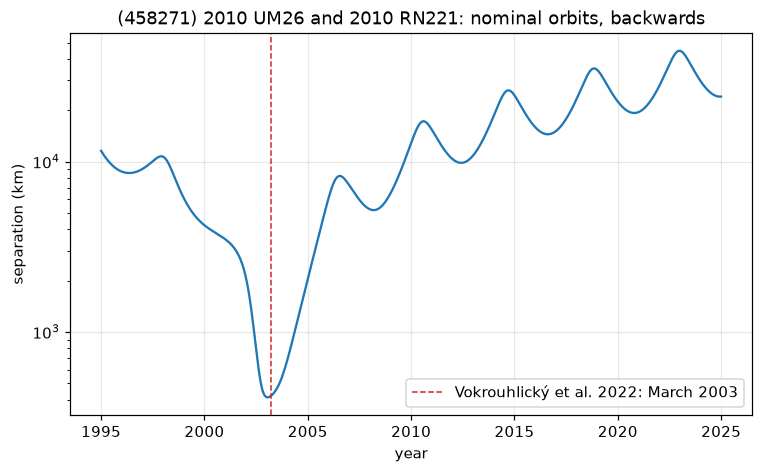

nominal orbits closest on 2003-01-21: 412 km


In [3]:
AU_KM = 1.495978707e8
T = lambda jd_tdb: Time(jd_tdb, format="jd", scale="tdb")     # TDB Julian dates as times

A_, B_ = fits["458271"], fits["2010 RN221"]
t = Time("1995-01-01").tdb.jd + np.arange(0, 30 * 365.25, 2.0)
sep = np.linalg.norm(pyroorb.propagate(A_, T(t))[:, :3] - pyroorb.propagate(B_, T(t))[:, :3], axis=1) * AU_KM
yr = T(t).decimalyear
k = sep.argmin()
plt.semilogy(yr, sep)
plt.axvline(2003.2, color="C3", ls="--", lw=1, label="Vokrouhlický et al. 2022: March 2003")
plt.xlabel("year"); plt.ylabel("separation (km)"); plt.legend()
plt.title("(458271) 2010 UM26 and 2010 RN221: nominal orbits, backwards")
plt.show()
print(f"nominal orbits closest on {T(t[k]).iso[:10]}: {sep[k]:,.0f} km")

The two nominal orbits run together into 2003 and apart again: before that date they were one
body, or two bodies within a few hundred km of each other. Now the same with uncertainty. We draw
150 clones of each orbit from its covariance, propagate all of them through 2000-2006 on a daily
grid, and for every one of the 22,801 clone pairs (151 × 151, the nominal orbits included) record the closest approach, when it happened,
and the relative speed at that moment.

The yardsticks: a Hill radius of about 230 km and an escape speed of about 0.5 m/s for an
850 m primary of density 2 g/cm³ (the paper's numbers). The published result: 99% of clone pairs
come within 1000 km, 99% at under 3 cm/s, in a half-year window around March 2003.

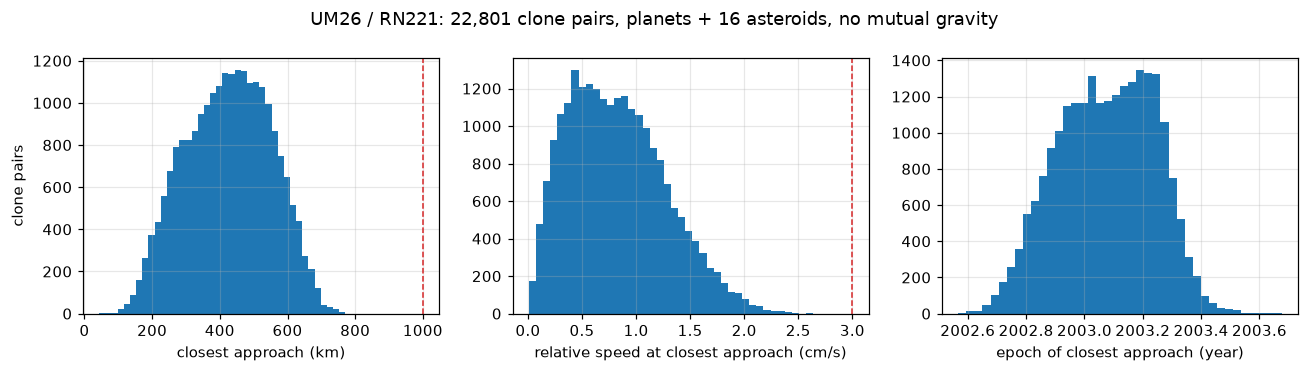

closest approach: median 430 km, 5-95% 216-626 km
relative speed  : median 0.8 cm/s, 95% below 1.6 cm/s
epoch           : 2003.08 (5-95%: 2002.80 - 2003.32)
within 1000 km AND under 3 cm/s: 100% of clone pairs   (published: 99%, March 2003)


In [4]:
def cloud(f, jd_tdb, n=150, seed=2003):
    """The nominal orbit, then n clones drawn from its covariance: (n_t, 1 + n, 6)."""
    nominal = pyroorb.propagate(f, T(jd_tdb))[:, None, :]
    return np.concatenate([nominal, pyroorb.sample_orbits(f, n, rng_seed=seed).propagate(T(jd_tdb))], axis=1)

tc = Time("2000-01-01").tdb.jd + np.arange(0, 6 * 365.25, 1.0)
A = cloud(A_, tc)                                   # (n_t, 151, 6)
B = cloud(B_, tc, seed=2004)
d = np.linalg.norm(A[:, :, None, :3] - B[:, None, :, :3], axis=3)          # (n_t, 151, 151) au
kmin = d.argmin(axis=0)                                                      # (151, 151)
i, j = np.indices(kmin.shape)
dmin = d[kmin, i, j] * AU_KM                                                 # km
vrel = np.linalg.norm(A[kmin, i, 3:] - B[kmin, j, 3:], axis=-1) * AU_KM / 86400 * 1e5   # cm/s
when = Time(tc[kmin], format="jd", scale="tdb").decimalyear

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(dmin.ravel(), bins=40, color="C0"); axes[0].set(xlabel="closest approach (km)", ylabel="clone pairs")
axes[1].hist(vrel.ravel(), bins=40, color="C0"); axes[1].set(xlabel="relative speed at closest approach (cm/s)")
axes[2].hist(when.ravel(), bins=40, color="C0"); axes[2].set(xlabel="epoch of closest approach (year)")
for ax in axes[:2]:
    ax.axvline([1000, 3][axes.tolist().index(ax)], color="C3", ls="--", lw=1)
plt.suptitle("UM26 / RN221: 22,801 clone pairs, planets + 16 asteroids, no mutual gravity")
plt.tight_layout(); plt.show()

ok = (dmin < 1000) & (vrel < 3)
lo, med, hi = np.percentile(when, [5, 50, 95])
print(f"closest approach: median {np.median(dmin):,.0f} km, 5-95% {np.percentile(dmin, 5):,.0f}-{np.percentile(dmin, 95):,.0f} km")
print(f"relative speed  : median {np.median(vrel):.1f} cm/s, 95% below {np.percentile(vrel, 95):.1f} cm/s")
print(f"epoch           : {med:.2f} (5-95%: {lo:.2f} - {hi:.2f})")
print(f"within 1000 km AND under 3 cm/s: {ok.mean():.0%} of clone pairs   (published: 99%, March 2003)")

From the public astrometry and a gravity-only backward integration, PyRoOrb finds the same
event the paper reports: the two bodies were within a few Hill radii of the primary, moving
apart at a centimetre per second, in early 2003. The paper's integration also includes the pair's own
mutual gravity, which pulls the closest clone flybys in to tens of km; the convergence epoch
is the same.

## 3. 2019 PR2 and 2019 QR6: the age that gravity alone cannot give

These two are on a Jupiter-family-comet-like orbit (*a* ≈ 5.8 au, *e* ≈ 0.80, *q* ≈ 1.16 au) and
their separation history is dominated by a Jupiter encounter. Propagate the nominal orbits back
450 years and show their separation and their distance from Jupiter. The 16-asteroid kernel covers
this span.

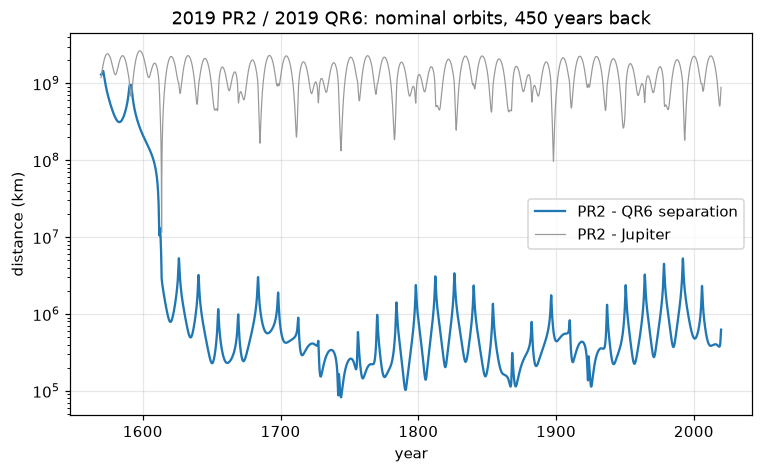

Jupiter encounter: 1613-09-09, PR2 at 11.49 million km, QR6 at 14.04 million km  (Fatka et al.: 11.5 and 13.9)


In [5]:
P_, Q_ = fits["2019 PR2"], fits["2019 QR6"]
jupiter = lambda jd_tdb: pyroorb.body_states("jupiter", T(jd_tdb))[:, :3]

tl = P_.epoch_tdb - np.arange(0, 450 * 365.25, 2.0)
XP, XQ = pyroorb.propagate(P_, T(tl))[:, :3], pyroorb.propagate(Q_, T(tl))[:, :3]
J = jupiter(tl)
yrl = Time(tl, format="jd", scale="tdb").decimalyear
fig, ax = plt.subplots()
ax.semilogy(yrl, np.linalg.norm(XP - XQ, axis=1) * AU_KM, label="PR2 - QR6 separation")
ax.semilogy(yrl, np.linalg.norm(XP - J, axis=1) * AU_KM, color="0.6", lw=0.8, label="PR2 - Jupiter")
ax.set(xlabel="year", ylabel="distance (km)", title="2019 PR2 / 2019 QR6: nominal orbits, 450 years back")
ax.legend(); plt.show()
kj = np.linalg.norm(XP - J, axis=1).argmin()
print(f"Jupiter encounter: {Time(tl[kj], format='jd', scale='tdb').iso[:10]}, "
      f"PR2 at {np.linalg.norm(XP - J, axis=1)[kj] * AU_KM / 1e6:.2f} million km, "
      f"QR6 at {np.linalg.norm(XQ - J, axis=1)[kj] * AU_KM / 1e6:.2f} million km  (Fatka et al.: 11.5 and 13.9)")

Now with clones. The encounter is far enough from Jupiter to be deterministic (the paper finds the
same), so a modest cloud suffices: 40 clones of each orbit, 2-day steps, the closest approach of
every pair searched between 200 and 450 years ago.

In [6]:
tp = P_.epoch_tdb - np.arange(200 * 365.25, 450 * 365.25, 2.0)
CP = cloud(P_, tp, 40, seed=1613)
CQ = cloud(Q_, tp, 40, seed=1614)
dp = np.linalg.norm(CP[:, :, None, :3] - CQ[:, None, :, :3], axis=3)
kp = dp.argmin(axis=0); i, j = np.indices(kp.shape)
dmin_p = dp[kp, i, j] * AU_KM
vrel_p = np.linalg.norm(CP[kp, i, 3:] - CQ[kp, j, 3:], axis=-1) * AU_KM / 86400 * 1000   # m/s
when_p = Time(tp[kp], format="jd", scale="tdb").decimalyear
print(f"gravity only, 1681 clone pairs: closest approach median {np.median(dmin_p):,.0f} km "
      f"(best {dmin_p.min():,.0f} km) at {np.median(vrel_p):.1f} m/s, around {np.median(when_p):.0f}")
print("Fatka et al. 2022, gravity only: no clone pair closer than ~80,000 km; Hill radius ~600 km")

gravity only, 1681 clone pairs: closest approach median 82,637 km (best 79,005 km) at 1.9 m/s, around 1744
Fatka et al. 2022, gravity only: no clone pair closer than ~80,000 km; Hill radius ~600 km


The orbits are a pair by every statistic, yet without extra forces they never meet: the closest
gravity-only clone pairs stay tens of thousands of km apart, forty-plus Hill radii. Fatka et al.
showed that only comet-like non-gravitational accelerations (Marsden $A_1, A_2, A_3$ at
$|A| \gtrsim 10^{-8}$ au/d², six orders of magnitude above Bennu's Yarkovsky push) bring the pair
together, about 300 years ago, so the "youngest pair" is also a claim that two dormant comets were
active for a while after they separated. A fit cannot see such forces today: both bodies looked
inactive down to 28th magnitude. That is the limit of what the orbits alone can say.

## Takeaways

* A pair's age is a backward-integration experiment that the orbit covariance feeds directly.
  For a benign main-belt pair, PyRoOrb's clone clouds reproduce the published convergence
  (UM26 / RN221: 2003, a few hundred km, centimetres per second).
* Whether the experiment works depends on the dynamics, not the astrometry: a planetary
  encounter on the way back, or forces the data cannot constrain, decouples the orbits from the
  age. PR2 / QR6 is a pair the orbits prove and an age the orbits cannot give.

**More to try.** Liu et al. (2026, ApJ 1007, 50) report two near-Earth pairs younger than a thousand
years, 2012 QG8 + 2024 GE1 and 2022 MY3 + 2022 OP8, and Wang & Xu (2025, AN 346, e70047) a
main-belt candidate, (434936) 2006 TW124 + 2015 HB287, under a thousand years old. The near-Earth
ones carry Earth encounters and a secondary with a weeks-long arc, so expect wide clone clouds.

**Caveats.** No mutual gravity and no Yarkovsky drift in the clone integrations (the UM26 / RN221
paper shows neither changes the epoch); the clone counts here are far below the papers' 10⁴ per
body; and the covariance is the fit's formal one, which notebook 07 compares with JPL's.